In [ ]:
import pandas as pd

df = pd.read_csv("/co2.csv")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/co2.csv'

In [ ]:
print("Dataset Shape:", df.shape)

NameError: name 'df' is not defined

In [ ]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Make', 'Model', 'Vehicle Class', 'Engine Size(L)', 'Cylinders', 'Transmission', 'Fuel Type', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)', 'Fuel Consumption Comb (mpg)', 'CO2 Emissions(g/km)']


                    GREENMILES-NG

                 Raw Dataset
                     ↓
             Check duplicates
                     ↓
       Check categorical consistency
                     ↓
          Check invalid values
                     ↓
             Check data types
                     ↓
             Clean Dataset
             

In [ ]:
import os

print(os.path.exists("/co2.csv"))
print(os.path.exists("/content/co2.csv"))

True
False


In [ ]:
df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [ ]:
missing = df.isnull().sum()

print("Missing values in each column:")
print(missing)

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64

Total missing values: 0


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 1103


In [ ]:
# Remove duplicate rows

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (6282, 12)


In [ ]:
# Check unique values in categorical columns

categorical_columns = [
    'Make',
    'Model',
    'Vehicle Class',
    'Transmission',
    'Fuel Type'
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].unique())


 Make
['ACURA' 'ALFA ROMEO' 'ASTON MARTIN' 'AUDI' 'BENTLEY' 'BMW' 'BUICK'
 'CADILLAC' 'CHEVROLET' 'CHRYSLER' 'DODGE' 'FIAT' 'FORD' 'GMC' 'HONDA'
 'HYUNDAI' 'INFINITI' 'JAGUAR' 'JEEP' 'KIA' 'LAMBORGHINI' 'LAND ROVER'
 'LEXUS' 'LINCOLN' 'MASERATI' 'MAZDA' 'MERCEDES-BENZ' 'MINI' 'MITSUBISHI'
 'NISSAN' 'PORSCHE' 'RAM' 'ROLLS-ROYCE' 'SCION' 'SMART' 'SRT' 'SUBARU'
 'TOYOTA' 'VOLKSWAGEN' 'VOLVO' 'GENESIS' 'BUGATTI']

 Model
['ILX' 'ILX HYBRID' 'MDX 4WD' ... 'Tacoma 4WD D-Cab TRD Off-Road/Pro'
 'Atlas Cross Sport 4MOTION' 'XC40 T4 AWD']

 Vehicle Class
['COMPACT' 'SUV - SMALL' 'MID-SIZE' 'TWO-SEATER' 'MINICOMPACT'
 'SUBCOMPACT' 'FULL-SIZE' 'STATION WAGON - SMALL' 'SUV - STANDARD'
 'VAN - CARGO' 'VAN - PASSENGER' 'PICKUP TRUCK - STANDARD' 'MINIVAN'
 'SPECIAL PURPOSE VEHICLE' 'STATION WAGON - MID-SIZE'
 'PICKUP TRUCK - SMALL']

 Transmission
['AS5' 'M6' 'AV7' 'AS6' 'AM6' 'A6' 'AM7' 'AV8' 'AS8' 'A7' 'A8' 'M7' 'A4'
 'M5' 'AV' 'A5' 'AS7' 'A9' 'AS9' 'AV6' 'AS4' 'AM5' 'AM8' 'AM9' 'AS10'
 'A10' 'AV10

In [ ]:
numerical_columns = [
    'Engine Size(L)',
    'Cylinders',
    'Fuel Consumption City (L/100 km)',
    'Fuel Consumption Hwy (L/100 km)',
    'Fuel Consumption Comb (L/100 km)',
    'Fuel Consumption Comb (mpg)',
    'CO2 Emissions(g/km)'
]

In [ ]:
# Check minimum and maximum values

df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Engine Size(L),6282.0,3.161812,1.365201,0.9,2.0,3.0,3.7,8.4
Cylinders,6282.0,5.618911,1.846250,3.0,4.0,6.0,6.0,16.0
Fuel Consumption City (L/100 km),6282.0,12.610220,3.553066,4.2,10.1,12.1,14.7,30.6
Fuel Consumption Hwy (L/100 km),6282.0,9.070583,2.278884,4.0,7.5,8.7,10.3,20.6
Fuel Consumption Comb (L/100 km),6282.0,11.017876,2.946876,4.1,8.9,10.6,12.7,26.1
Fuel Consumption Comb (mpg),6282.0,27.411016,7.245318,11.0,22.0,27.0,32.0,69.0
CO2 Emissions(g/km),6282.0,251.157752,59.290426,96.0,208.0,246.0,289.0,522.0


In [ ]:
# Count non-positive values

for column in numerical_columns:
    count = (df[column] <= 0).sum()
    print(f"{column}: {count}")

Engine Size(L): 0
Cylinders: 0
Fuel Consumption City (L/100 km): 0
Fuel Consumption Hwy (L/100 km): 0
Fuel Consumption Comb (L/100 km): 0
Fuel Consumption Comb (mpg): 0
CO2 Emissions(g/km): 0


In [ ]:
print(df.dtypes)

Make                                 object
Model                                object
Vehicle Class                        object
Engine Size(L)                      float64
Cylinders                             int64
Transmission                         object
Fuel Type                            object
Fuel Consumption City (L/100 km)    float64
Fuel Consumption Hwy (L/100 km)     float64
Fuel Consumption Comb (L/100 km)    float64
Fuel Consumption Comb (mpg)           int64
CO2 Emissions(g/km)                   int64
dtype: object


Step 3

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("EDA Started")

EDA Started


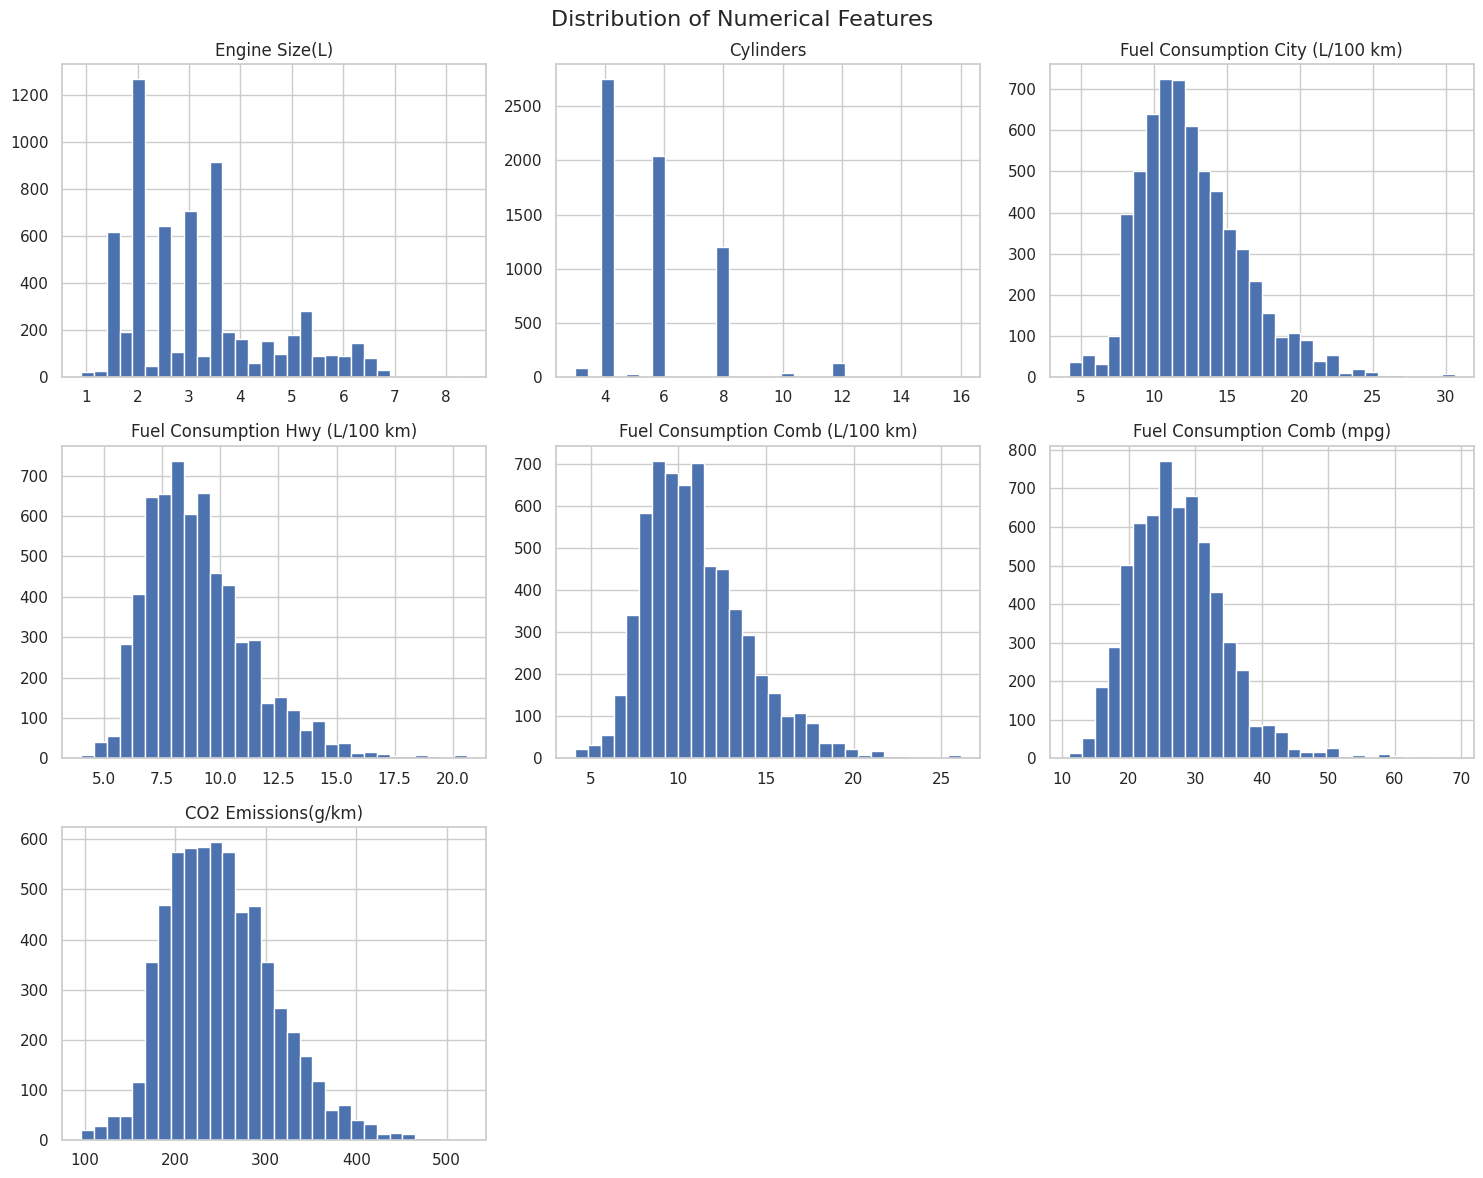

In [ ]:
numerical_columns = [
    'Engine Size(L)',
    'Cylinders',
    'Fuel Consumption City (L/100 km)',
    'Fuel Consumption Hwy (L/100 km)',
    'Fuel Consumption Comb (L/100 km)',
    'Fuel Consumption Comb (mpg)',
    'CO2 Emissions(g/km)'
]

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

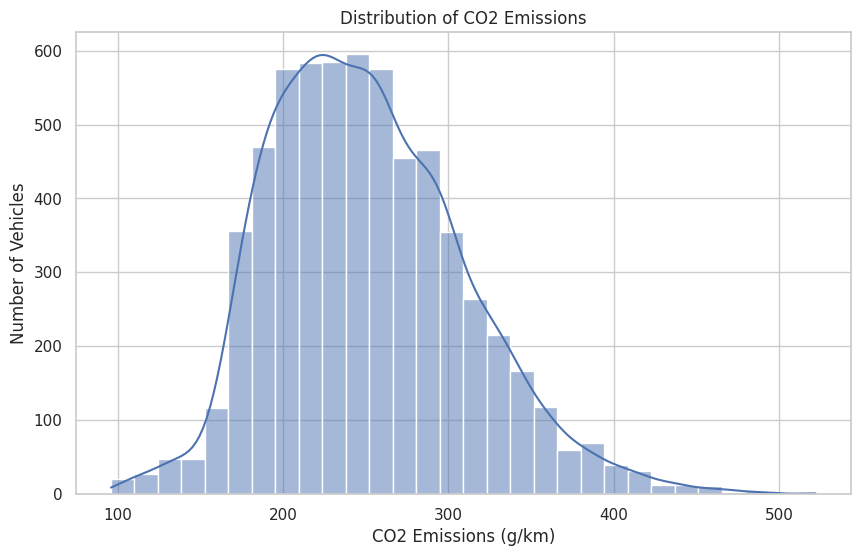

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['CO2 Emissions(g/km)'],
    bins=30,
    kde=True
)

plt.title("Distribution of CO2 Emissions")
plt.xlabel("CO2 Emissions (g/km)")
plt.ylabel("Number of Vehicles")

plt.show()

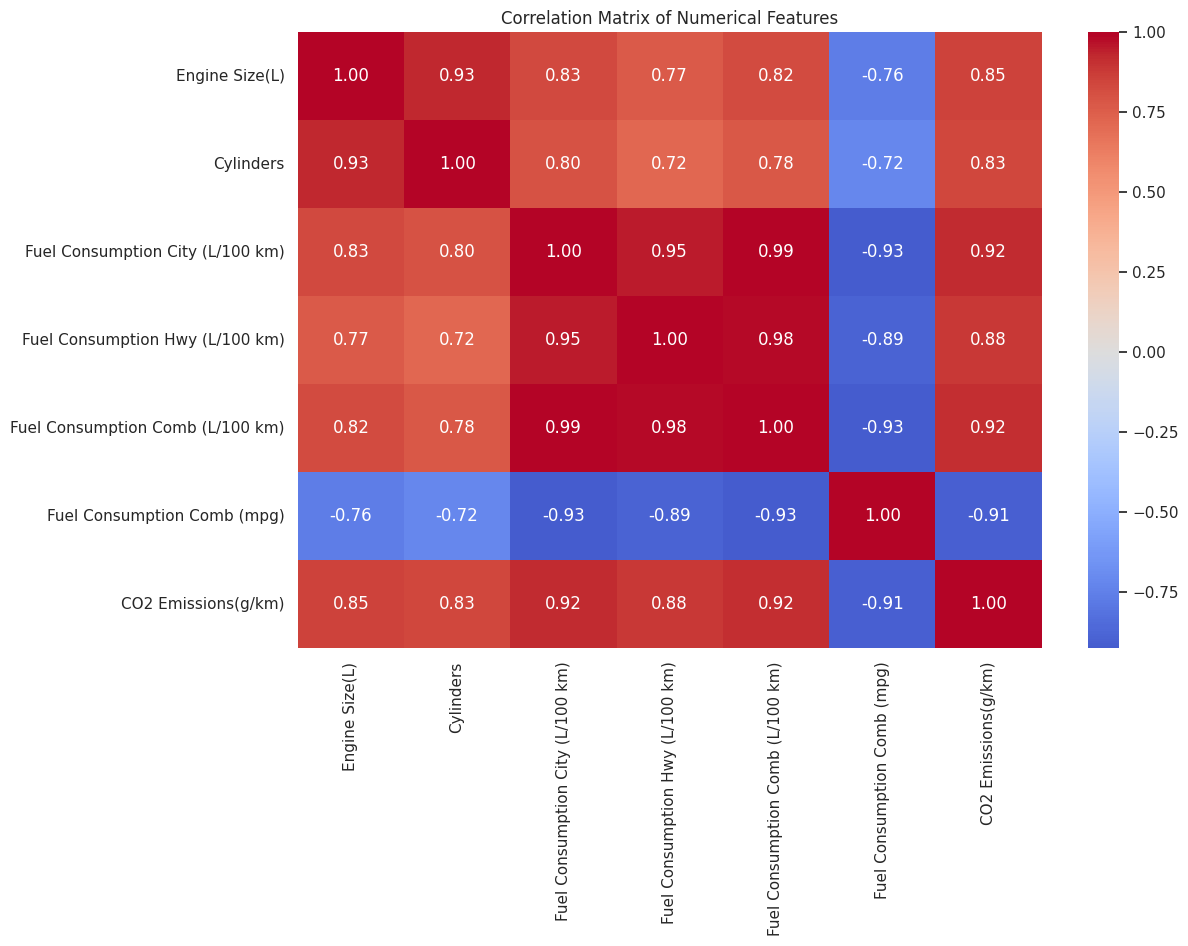

In [ ]:
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")

plt.show()

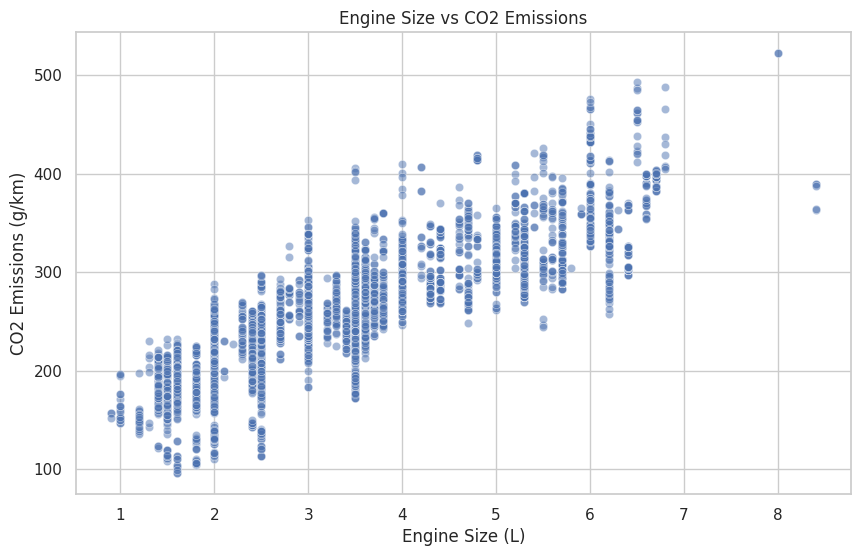

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Engine Size(L)',
    y='CO2 Emissions(g/km)',
    alpha=0.5
)

plt.title("Engine Size vs CO2 Emissions")
plt.xlabel("Engine Size (L)")
plt.ylabel("CO2 Emissions (g/km)")

plt.show()

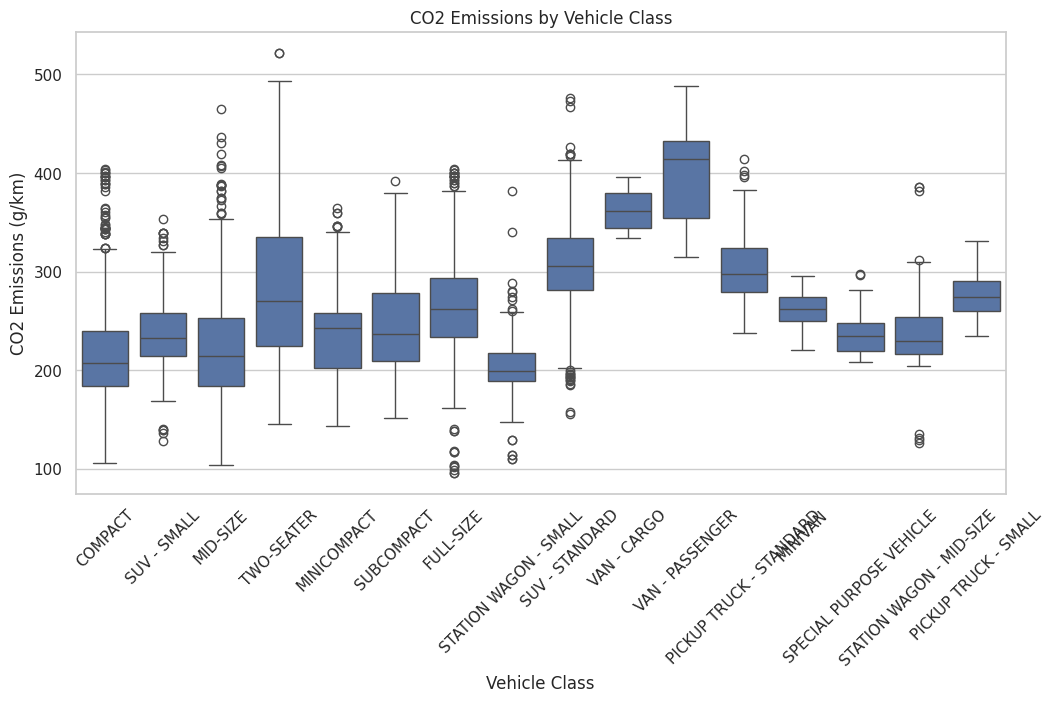

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Vehicle Class',
    y='CO2 Emissions(g/km)'
)

plt.title("CO2 Emissions by Vehicle Class")
plt.xlabel("Vehicle Class")
plt.ylabel("CO2 Emissions (g/km)")

plt.xticks(rotation=45)

plt.show()

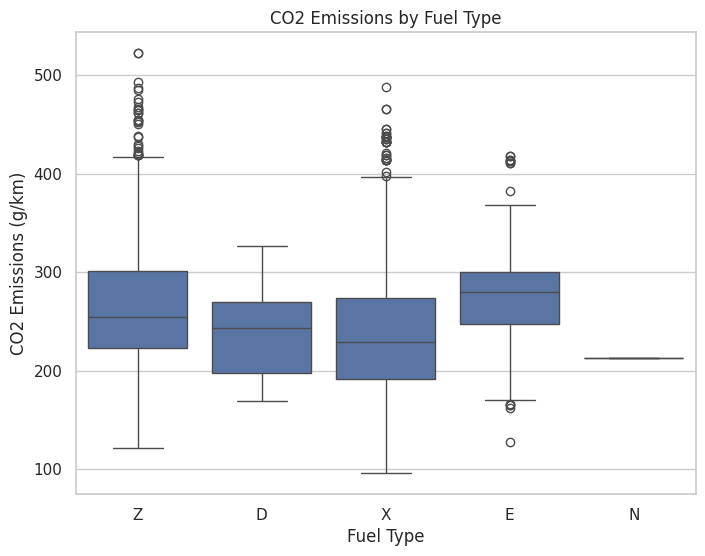

In [ ]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='Fuel Type',
    y='CO2 Emissions(g/km)'
)

plt.title("CO2 Emissions by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("CO2 Emissions (g/km)")

plt.show()

In [ ]:
print("Vehicle Class Distribution:")
print(df['Vehicle Class'].value_counts())

Vehicle Class Distribution:
Vehicle Class
SUV - SMALL                 1006
MID-SIZE                     983
COMPACT                      903
SUV - STANDARD               613
SUBCOMPACT                   533
FULL-SIZE                    508
PICKUP TRUCK - STANDARD      475
TWO-SEATER                   381
MINICOMPACT                  274
STATION WAGON - SMALL        214
PICKUP TRUCK - SMALL         133
VAN - PASSENGER               66
SPECIAL PURPOSE VEHICLE       65
MINIVAN                       61
STATION WAGON - MID-SIZE      45
VAN - CARGO                   22
Name: count, dtype: int64


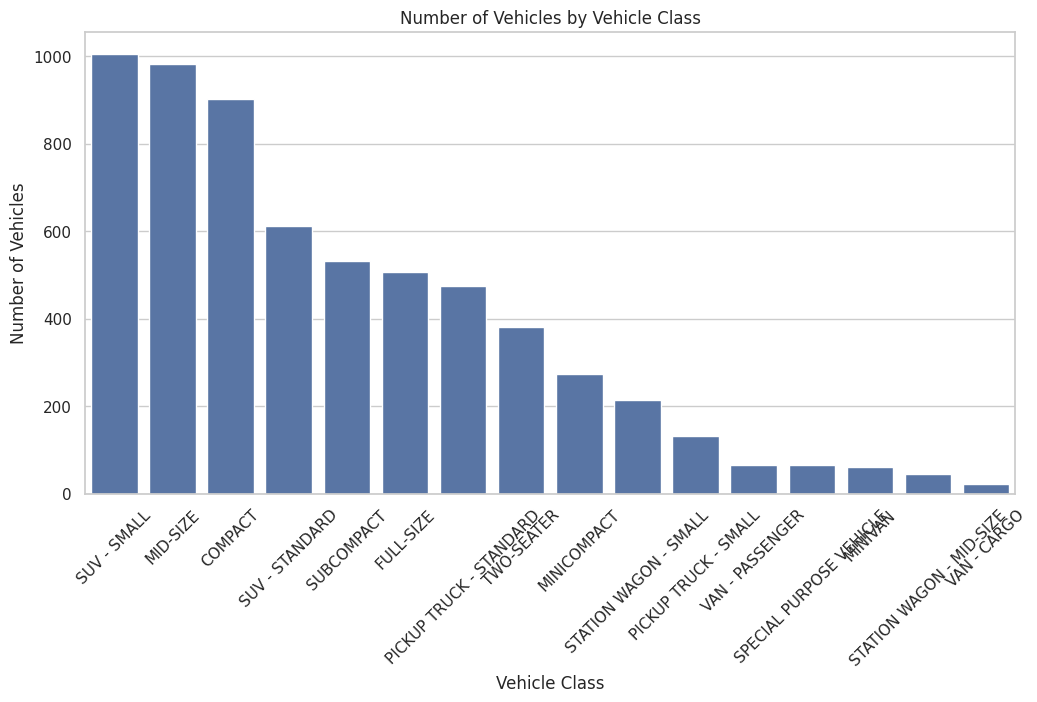

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='Vehicle Class',
    order=df['Vehicle Class'].value_counts().index
)

plt.title("Number of Vehicles by Vehicle Class")
plt.xlabel("Vehicle Class")
plt.ylabel("Number of Vehicles")

plt.xticks(rotation=45)

plt.show()

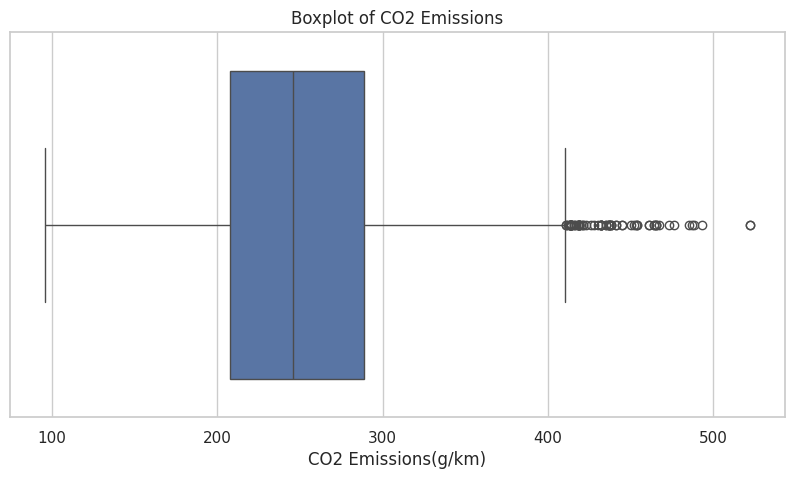

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['CO2 Emissions(g/km)']
)

plt.title("Boxplot of CO2 Emissions")

plt.show()

In [ ]:
print("Statistical Summary:")
display(df[numerical_columns].describe())

Statistical Summary:


,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
count,6282.000000,6282.000000,6282.000000,6282.000000,6282.000000,6282.000000,6282.000000
mean,3.161812,5.618911,12.610220,9.070583,11.017876,27.411016,251.157752
std,1.365201,1.846250,3.553066,2.278884,2.946876,7.245318,59.290426
min,0.900000,3.000000,4.200000,4.000000,4.100000,11.000000,96.000000
25%,2.000000,4.000000,10.100000,7.500000,8.900000,22.000000,208.000000
50%,3.000000,6.000000,12.100000,8.700000,10.600000,27.000000,246.000000
75%,3.700000,6.000000,14.700000,10.300000,12.700000,32.000000,289.000000
max,8.400000,16.000000,30.600000,20.600000,26.100000,69.000000,522.000000


In [ ]:
co2_correlation = (
    df[numerical_columns]
    .corr()['CO2 Emissions(g/km)']
    .sort_values(ascending=False)
)

print("Correlation with CO2 Emissions:")
print(co2_correlation)

Correlation with CO2 Emissions:
CO2 Emissions(g/km)                 1.000000
Fuel Consumption City (L/100 km)    0.918756
Fuel Consumption Comb (L/100 km)    0.916840
Fuel Consumption Hwy (L/100 km)     0.883424
Engine Size(L)                      0.854802
Cylinders                           0.834687
Fuel Consumption Comb (mpg)        -0.906783
Name: CO2 Emissions(g/km), dtype: float64


Step 4

In [ ]:
df_fe = df.copy()

print("Feature Engineering Dataset Shape:", df_fe.shape)

Feature Engineering Dataset Shape: (6282, 12)


In [ ]:
df_fe['City_Hwy_Difference'] = (
    df_fe['Fuel Consumption City (L/100 km)']
    - df_fe['Fuel Consumption Hwy (L/100 km)']
)

print(df_fe[['Fuel Consumption City (L/100 km)',
             'Fuel Consumption Hwy (L/100 km)',
             'City_Hwy_Difference']].head())

   Fuel Consumption City (L/100 km)  Fuel Consumption Hwy (L/100 km)  \
0                               9.9                              6.7   
1                              11.2                              7.7   
2                               6.0                              5.8   
3                              12.7                              9.1   
4                              12.1                              8.7   

   City_Hwy_Difference  
0                  3.2  
1                  3.5  
2                  0.2  
3                  3.6  
4                  3.4  


In [ ]:
df_fe['Engine_Per_Cylinder'] = (
    df_fe['Engine Size(L)'] / df_fe['Cylinders']
)

print(df_fe[['Engine Size(L)',
             'Cylinders',
             'Engine_Per_Cylinder']].head())

   Engine Size(L)  Cylinders  Engine_Per_Cylinder
0             2.0          4             0.500000
1             2.4          4             0.600000
2             1.5          4             0.375000
3             3.5          6             0.583333
4             3.5          6             0.583333


In [ ]:
new_features = [
    'City_Hwy_Difference',
    'Engine_Per_Cylinder'
]

print("New Features:")
print(df_fe[new_features].describe())

New Features:
       City_Hwy_Difference  Engine_Per_Cylinder
count          6282.000000          6282.000000
mean              3.539637             0.548436
std               1.555671             0.093770
min              -0.900000             0.250000
25%               2.500000             0.500000
50%               3.400000             0.525000
75%               4.400000             0.600000
max              10.800000             0.850000


In [ ]:
feature_check = df_fe[
    numerical_columns + new_features
].corr()['CO2 Emissions(g/km)'].sort_values(ascending=False)

print(feature_check)

CO2 Emissions(g/km)                 1.000000
Fuel Consumption City (L/100 km)    0.918756
Fuel Consumption Comb (L/100 km)    0.916840
Fuel Consumption Hwy (L/100 km)     0.883424
Engine Size(L)                      0.854802
Cylinders                           0.834687
City_Hwy_Difference                 0.804270
Engine_Per_Cylinder                 0.588923
Fuel Consumption Comb (mpg)        -0.906783
Name: CO2 Emissions(g/km), dtype: float64


step 5


In [ ]:
# Target variable
target = 'CO2 Emissions(g/km)'

# Separate input features and target
X = df_fe.drop(columns=[target])
y = df_fe[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget:")
print(y.head())

X shape: (6282, 13)
y shape: (6282,)

Target:
0    196
1    221
2    136
3    255
4    244
Name: CO2 Emissions(g/km), dtype: int64


In [ ]:
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel Type']

Numerical Features:
['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)', 'Fuel Consumption Comb (mpg)', 'City_Hwy_Difference', 'Engine_Per_Cylinder']


In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_encoded = encoder.fit_transform(
    X[categorical_features]
)

print("Encoded categorical shape:", X_encoded.shape)

Encoded categorical shape: (6282, 2143)


In [ ]:
import numpy as np

X_numerical = X[numerical_features].values

X_processed = np.hstack([
    X_numerical,
    X_encoded
])

print("Final processed feature shape:", X_processed.shape)

Final processed feature shape: (6282, 2151)


In [ ]:
print("Missing values:", np.isnan(X_processed).sum())
print("Infinite values:", np.isinf(X_processed).sum())

Missing values: 0
Infinite values: 0


In [ ]:
print("Target missing values:", y.isnull().sum())
print("Target minimum:", y.min())
print("Target maximum:", y.max())

Target missing values: 0
Target minimum: 96
Target maximum: 522


Step 6


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (5025, 13)
Testing data shape: (1257, 13)

Training target shape: (5025,)
Testing target shape: (1257,)


In [ ]:
print("Training target statistics:")
print(y_train.describe())

print("\nTesting target statistics:")
print(y_test.describe())

Training target statistics:
count    5025.000000
mean      250.806169
std        59.087870
min        96.000000
25%       207.000000
50%       245.000000
75%       289.000000
max       522.000000
Name: CO2 Emissions(g/km), dtype: float64

Testing target statistics:
count    1257.000000
mean      252.563246
std        60.096547
min       103.000000
25%       209.000000
50%       247.000000
75%       291.000000
max       522.000000
Name: CO2 Emissions(g/km), dtype: float64


In [ ]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Total samples:", len(X_train) + len(X_test))

Training samples: 5025
Testing samples: 1257
Total samples: 6282


Step 7


In [ ]:
!pip install ngboost

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 5.7 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=1f4cdfaacbea39bd39eca0cdd58de46bd4a834bbe69d863b79f61b7b2718a997
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma


In [ ]:
from ngboost import NGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
from sklearn.preprocessing import OneHotEncoder
import numpy as np

encoder_ngb = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit ONLY on training data
X_train_cat = encoder_ngb.fit_transform(
    X_train[categorical_features]
)

# Transform test data using the same encoder
X_test_cat = encoder_ngb.transform(
    X_test[categorical_features]
)

# Numerical features
X_train_num = X_train[numerical_features].values
X_test_num = X_test[numerical_features].values

# Combine numerical + categorical
X_train_processed = np.hstack([
    X_train_num,
    X_train_cat
])

X_test_processed = np.hstack([
    X_test_num,
    X_test_cat
])

print("X_train processed:", X_train_processed.shape)
print("X_test processed:", X_test_processed.shape)

X_train processed: (5025, 1989)
X_test processed: (1257, 1989)


In [ ]:
ngb_model = NGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    random_state=42,
    verbose=False
)

ngb_model.fit(
    X_train_processed,
    y_train
)

print("NGBoost model training completed successfully!")

NGBoost model training completed successfully!


In [ ]:
# STEP 8: Evaluate NGBoost Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions
y_pred = ngb_model.predict(X_test_processed)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("===== NGBoost Model Evaluation =====")
print(f"MAE  : {mae:.2f} g/km")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} g/km")
print(f"R²   : {r2:.4f}")

===== NGBoost Model Evaluation =====
MAE  : 2.63 g/km
MSE  : 16.91
RMSE : 4.11 g/km
R²   : 0.9953


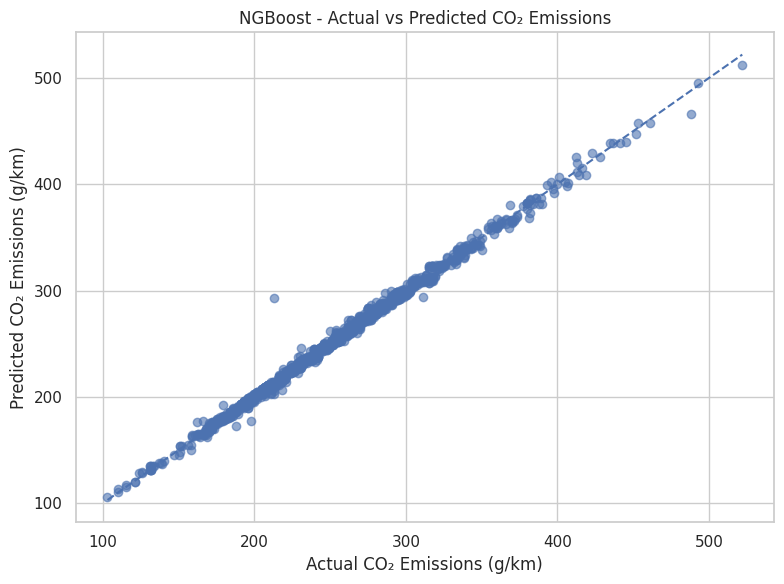

In [ ]:
# Actual vs Predicted CO2

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual CO₂ Emissions (g/km)")
plt.ylabel("Predicted CO₂ Emissions (g/km)")
plt.title("NGBoost - Actual vs Predicted CO₂ Emissions")

plt.tight_layout()
plt.show()

In [ ]:
print("X_train_processed:", X_train_processed.shape)
print("X_test_processed :", X_test_processed.shape)
print("y_train           :", y_train.shape)
print("y_test            :", y_test.shape)


X_train_processed: (5025, 1989)
X_test_processed : (1257, 1989)
y_train           : (5025,)
y_test            : (1257,)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

In [ ]:
# Create models

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

print("\nAll comparison models trained successfully!")

Training Linear Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...
Training Extra Trees...

All comparison models trained successfully!


Step 9
**bold text**

In [ ]:
results.append({
    "Model": "NGBoost",
    "MAE": mae if False else 2.63,
    "MSE": 16.95,
    "RMSE": 4.12,
    "R²": 0.9993
})

In [ ]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,MAE,MSE,RMSE,R²
0,NGBoost,2.630000,16.950000,4.120000,0.999300
1,Random Forest,2.181029,15.497518,3.936689,0.995706
2,Extra Trees,2.166363,17.133516,4.139265,0.995252
3,Decision Tree,2.211615,17.177009,4.144516,0.995240
4,Gradient Boosting,3.125422,24.398589,4.939493,0.993239
5,Linear Regression,3.582556,32.030175,5.659521,0.991124


In [ ]:
ngb_mae = mean_absolute_error(y_test, y_pred)
ngb_mse = mean_squared_error(y_test, y_pred)
ngb_rmse = np.sqrt(ngb_mse)
ngb_r2 = r2_score(y_test, y_pred)

results.append({
    "Model": "NGBoost",
    "MAE": ngb_mae,
    "MSE": ngb_mse,
    "RMSE": ngb_rmse,
    "R²": ngb_r2
})

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,MAE,MSE,RMSE,R²
0,NGBoost,2.630000,16.950000,4.120000,0.999300
1,Random Forest,2.181029,15.497518,3.936689,0.995706
2,NGBoost,2.630363,16.910790,4.112273,0.995314
3,Extra Trees,2.166363,17.133516,4.139265,0.995252
4,Decision Tree,2.211615,17.177009,4.144516,0.995240
5,Gradient Boosting,3.125422,24.398589,4.939493,0.993239
6,Linear Regression,3.582556,32.030175,5.659521,0.991124


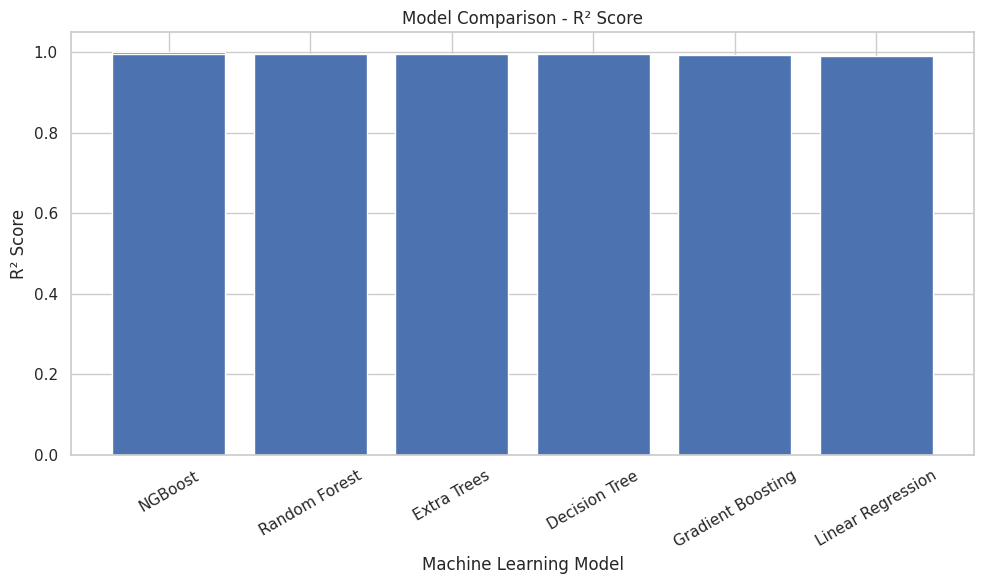

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["R²"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.title("Model Comparison - R² Score")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

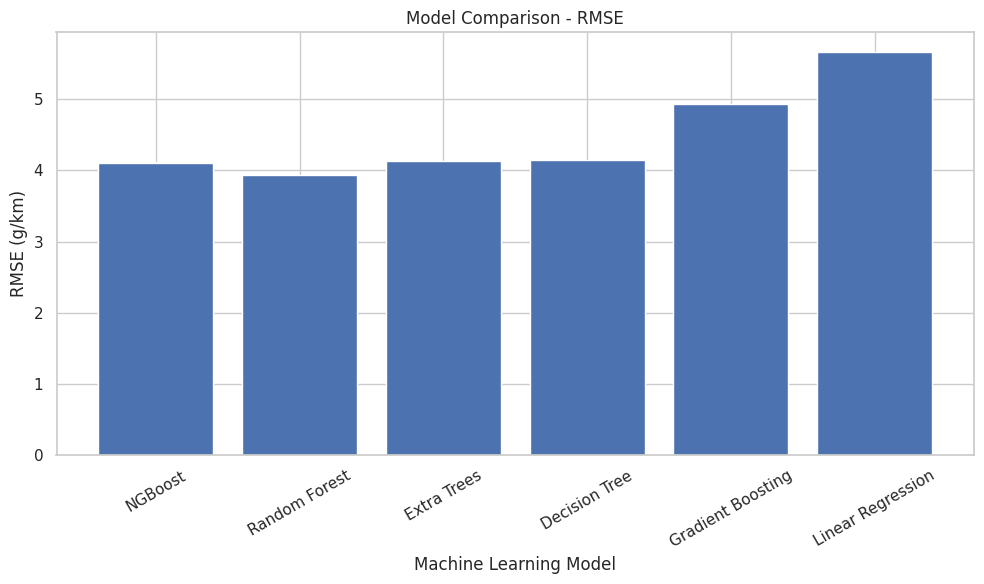

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["RMSE"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE (g/km)")
plt.title("Model Comparison - RMSE")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 10 - Baseline NGBoost Performance

baseline_mae = ngb_mae
baseline_rmse = ngb_rmse
baseline_r2 = ngb_r2

print("===== BASELINE NGBOOST =====")
print("n_estimators :", 500)
print("learning_rate:", 0.03)
print(f"MAE          : {baseline_mae:.4f}")
print(f"RMSE         : {baseline_rmse:.4f}")
print(f"R²           : {baseline_r2:.4f}")

===== BASELINE NGBOOST =====
n_estimators : 500
learning_rate: 0.03
MAE          : 2.6304
RMSE         : 4.1123
R²           : 0.9953


In [ ]:
from ngboost import NGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Hyperparameter combinations
param_combinations = [
    (300, 0.01),
    (300, 0.03),
    (500, 0.01),
    (500, 0.03),
    (500, 0.05),
    (700, 0.03),
    (700, 0.05),
    (1000, 0.03),
    (1000, 0.05)
]

tuning_results = []

for n_est, lr in param_combinations:

    print(f"Testing n_estimators={n_est}, learning_rate={lr}")

    model = NGBRegressor(
        n_estimators=n_est,
        learning_rate=lr,
        random_state=42,
        verbose=False
    )

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    tuning_results.append({
        "n_estimators": n_est,
        "learning_rate": lr,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

print("\nHyperparameter tuning completed!")

Testing n_estimators=300, learning_rate=0.01
Testing n_estimators=300, learning_rate=0.03
Testing n_estimators=500, learning_rate=0.01
Testing n_estimators=500, learning_rate=0.03
Testing n_estimators=500, learning_rate=0.05
Testing n_estimators=700, learning_rate=0.03
Testing n_estimators=700, learning_rate=0.05
Testing n_estimators=1000, learning_rate=0.03
Testing n_estimators=1000, learning_rate=0.05

Hyperparameter tuning completed!


In [ ]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

tuning_df

,n_estimators,learning_rate,MAE,MSE,RMSE,R²
0,1000,0.03,2.557910,16.150697,4.018793,0.995525
1,1000,0.05,2.540757,16.515694,4.063951,0.995423
2,700,0.03,2.600138,16.595181,4.073718,0.995401
3,700,0.05,2.556349,16.743708,4.091908,0.995360
4,500,0.03,2.626131,16.855689,4.105568,0.995329
5,500,0.05,2.599349,17.136188,4.139588,0.995251
6,300,0.03,2.681900,17.467837,4.179454,0.995160
7,500,0.01,2.762436,18.582112,4.310697,0.994851
8,300,0.01,3.023439,22.580146,4.751857,0.993743


In [ ]:
best_result = tuning_df.iloc[0]

print("===== BEST NGBOOST PARAMETERS =====")

print("n_estimators :", int(best_result["n_estimators"]))
print("learning_rate:", best_result["learning_rate"])

print(f"MAE  : {best_result['MAE']:.4f}")
print(f"RMSE : {best_result['RMSE']:.4f}")
print(f"R²   : {best_result['R²']:.4f}")

===== BEST NGBOOST PARAMETERS =====
n_estimators : 1000
learning_rate: 0.03
MAE  : 2.5579
RMSE : 4.0188
R²   : 0.9955


In [ ]:
# STEP 11: Train Final NGBoost Model

from ngboost import NGBRegressor

final_ngb_model = NGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    random_state=42,
    verbose=False
)

final_ngb_model.fit(
    X_train_processed,
    y_train
)

print("Final NGBoost model trained successfully!")

Final NGBoost model trained successfully!


In [ ]:
# Evaluate Final NGBoost Model

final_predictions = final_ngb_model.predict(X_test_processed)

final_mae = mean_absolute_error(y_test, final_predictions)
final_mse = mean_squared_error(y_test, final_predictions)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, final_predictions)

print("===== FINAL NGBOOST MODEL =====")
print(f"MAE  : {final_mae:.4f} g/km")
print(f"MSE  : {final_mse:.4f}")
print(f"RMSE : {final_rmse:.4f} g/km")
print(f"R²   : {final_r2:.4f}")

===== FINAL NGBOOST MODEL =====
MAE  : 2.5654 g/km
MSE  : 16.2291
RMSE : 4.0285 g/km
R²   : 0.9955
